# Analysis Notebook for main_2_2D.py Results

This notebook analyzes CSV results from `main_2_2D.py` simulations comparing **empathic** vs **non-empathic** agents.

## Configuration
- **Agents**: 5
- **Grid**: 5x5
- **Resources**: 10
- **Empathic Penalty**: -1.0
- **Empathy Alpha**: 0.5 (empathic) vs 0.0 (non-empathic)
- **Seeds**: Non-empathic=42, Empathic=123

## Metrics Analyzed
- **Depletion Step**: Step at which resources first reach 0
- **Avg Resources During Episode**: Mean resource count throughout episode
- **Resources Remaining**: Resources left at episode end
- **Gini Coefficients**: Inequality in consumption and satisfaction
- **Total Consumption**: Resources consumed per episode
- **Empathic Penalty Events**: Number of empathic penalties triggered
- **Inter-Agent Distance**: Average Manhattan distance between agents

In [1]:
import numpy as np
import pandas as pd
import os
import re
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("Imports completed successfully!")

Imports completed successfully!


## Configuration

In [2]:
# Configuration matching main_2_2D.py
NB_AGENTS = 5
GRID_SIZE = 5
NUM_RESOURCES = 10
EMPATHIC_PENALTY = -1.0
NUM_EPISODES = 300
MAX_STEPS = 200

# Results folder
RESULTS_FOLDER = "2D_simulation_results"

print(f"Configuration:")
print(f"  Agents: {NB_AGENTS}")
print(f"  Grid: {GRID_SIZE}x{GRID_SIZE}")
print(f"  Resources: {NUM_RESOURCES}")
print(f"  Empathic Penalty: {EMPATHIC_PENALTY}")
print(f"  Episodes: {NUM_EPISODES}")
print(f"  Max Steps: {MAX_STEPS}")

Configuration:
  Agents: 5
  Grid: 5x5
  Resources: 10
  Empathic Penalty: -1.0
  Episodes: 300
  Max Steps: 200


## Load Data

In [3]:
# Find and load CSV files from main_2_2D.py
# Pattern: results_000_300_grid5_agents5_resources10_vision2_exploit1.0_penalty-1.0_alpha{alpha}_...

def load_results(folder_path):
    """Load all CSV files matching main_2_2D.py output format."""
    all_data = []
    
    if not os.path.exists(folder_path):
        print(f"Folder not found: {folder_path}")
        return pd.DataFrame()
    
    # Pattern to match main_2_2D.py output files
    pattern = re.compile(
        r"results_\d+_\d+_grid\d+_agents5_.*_penalty-1\.0_alpha([\d.]+)_.*_episode_summary\.csv"
    )
    
    for filename in os.listdir(folder_path):
        if not filename.endswith('.csv'):
            continue
        
        match = pattern.match(filename)
        if match:
            alpha = float(match.group(1))
            filepath = os.path.join(folder_path, filename)
            
            try:
                df = pd.read_csv(filepath)
                df['alpha'] = alpha
                df['condition'] = 'Empathic' if alpha > 0 else 'Non-Empathic'
                df['filename'] = filename
                all_data.append(df)
                print(f"Loaded: {filename} (alpha={alpha}, {len(df)} rows)")
            except Exception as e:
                print(f"Error loading {filename}: {e}")
    
    if not all_data:
        print("No matching files found.")
        return pd.DataFrame()
    
    return pd.concat(all_data, ignore_index=True)


# Load data
df = load_results(RESULTS_FOLDER)

if len(df) > 0:
    print(f"\nTotal rows loaded: {len(df)}")
    print(f"Columns: {list(df.columns)}")
    print(f"\nConditions found:")
    for alpha in sorted(df['alpha'].unique()):
        alpha_data = df[df['alpha'] == alpha]
        total_episodes = len(alpha_data)
        num_simulations = alpha_data['simulation_number'].nunique()
        episodes_per_sim = total_episodes // num_simulations if num_simulations > 0 else 0
        print(f"  Alpha={alpha}: {total_episodes} episodes from {num_simulations} simulation(s) ({episodes_per_sim} episodes/sim)")

Loaded: results_000_300_grid5_agents5_resources10_vision2_exploit1.0_penalty-1.0_alpha0.0_loop-0.05_0.002_0.99_1.0_0.995_0.05_32_128_20_223505_episode_summary.csv (alpha=0.0, 300 rows)
Loaded: results_000_300_grid5_agents5_resources10_vision2_exploit1.0_penalty-1.0_alpha0.0_loop-0.05_0.002_0.99_1.0_0.995_0.05_32_128_20_351344_episode_summary.csv (alpha=0.0, 300 rows)
Loaded: results_000_300_grid5_agents5_resources10_vision2_exploit1.0_penalty-1.0_alpha0.5_loop-0.05_0.002_0.99_1.0_0.995_0.05_32_128_20_175612_episode_summary.csv (alpha=0.5, 300 rows)
Loaded: results_000_300_grid5_agents5_resources10_vision2_exploit1.0_penalty-1.0_alpha0.5_loop-0.05_0.002_0.99_1.0_0.995_0.05_32_128_20_614618_episode_summary.csv (alpha=0.5, 300 rows)
Loaded: results_001_300_grid5_agents5_resources10_vision2_exploit1.0_penalty-1.0_alpha0.0_loop-0.05_0.002_0.99_1.0_0.995_0.05_32_128_20_614618_episode_summary.csv (alpha=0.0, 300 rows)
Loaded: results_001_300_grid5_agents5_resources10_vision2_exploit1.0_penalt

## Summary Statistics

In [4]:
def print_summary(name, data):
    """Print summary statistics for a condition."""
    print(f"\n{'='*50}")
    print(f"{name}")
    print(f"{'='*50}")
    print(f"Resource Depletion Step:    {data['depletion_step'].mean():.1f} +/- {data['depletion_step'].std():.1f}")
    print(f"Resources Remaining:        {data['resources_remaining'].mean():.2f} +/- {data['resources_remaining'].std():.2f}")
    print(f"Avg Resources During Ep:    {data['avg_resources_during_episode'].mean():.2f} +/- {data['avg_resources_during_episode'].std():.2f}")
    print(f"Total Consumption:          {data['total_consumption'].mean():.1f} +/- {data['total_consumption'].std():.1f}")
    print(f"Gini (Consumption):         {data['gini_consumption'].mean():.3f} +/- {data['gini_consumption'].std():.3f}")
    print(f"Gini (Satisfaction):        {data['gini_satisfaction'].mean():.3f} +/- {data['gini_satisfaction'].std():.3f}")
    print(f"Avg Inter-Agent Distance:   {data['avg_inter_agent_distance'].mean():.2f} +/- {data['avg_inter_agent_distance'].std():.2f}")
    print(f"Empathic Penalty Events:    {data['empathic_penalties_count'].mean():.1f} +/- {data['empathic_penalties_count'].std():.1f}")


if len(df) > 0:
    for alpha in sorted(df['alpha'].unique()):
        condition_name = 'EMPATHIC AGENTS (alpha=0.5)' if alpha > 0 else 'NON-EMPATHIC AGENTS (alpha=0.0)'
        print_summary(condition_name, df[df['alpha'] == alpha])


NON-EMPATHIC AGENTS (alpha=0.0)
Resource Depletion Step:    118.2 +/- 65.6
Resources Remaining:        1.39 +/- 2.59
Avg Resources During Ep:    5.13 +/- 1.89
Total Consumption:          26.8 +/- 10.1
Gini (Consumption):         0.289 +/- 0.115
Gini (Satisfaction):        0.566 +/- 0.342
Avg Inter-Agent Distance:   3.42 +/- 0.50
Empathic Penalty Events:    0.0 +/- 0.0

EMPATHIC AGENTS (alpha=0.5)
Resource Depletion Step:    180.3 +/- 49.4
Resources Remaining:        6.39 +/- 3.35
Avg Resources During Ep:    7.59 +/- 2.13
Total Consumption:          16.5 +/- 9.0
Gini (Consumption):         0.295 +/- 0.120
Gini (Satisfaction):        0.212 +/- 0.345
Avg Inter-Agent Distance:   3.16 +/- 0.58
Empathic Penalty Events:    3.4 +/- 2.8


## Comparison (Last N Episodes)

In [5]:
last_n = 20

if len(df) > 0 and len(df['alpha'].unique()) >= 2:
    max_episode = df['episode'].max()
    last_episodes = df[df['episode'] > max_episode - last_n]
    
    ne_data = last_episodes[last_episodes['alpha'] == 0.0]
    e_data = last_episodes[last_episodes['alpha'] > 0]
    
    print(f"{'='*60}")
    print(f"COMPARISON: Last {last_n} Episodes")
    print(f"{'='*60}")
    
    metrics = [
        ('Depletion Step', 'depletion_step'),
        ('Resources Remaining', 'resources_remaining'),
        ('Avg Resources During Episode', 'avg_resources_during_episode'),
        ('Total Consumption', 'total_consumption'),
        ('Gini (Consumption)', 'gini_consumption'),
        ('Gini (Satisfaction)', 'gini_satisfaction'),
        ('Avg Inter-Agent Distance', 'avg_inter_agent_distance'),
        ('Empathic Penalty Events', 'empathic_penalties_count'),
    ]
    
    for name, col in metrics:
        ne_val = ne_data[col].mean()
        e_val = e_data[col].mean()
        diff = e_val - ne_val
        pct = (diff / (ne_val + 1e-6)) * 100
        
        print(f"\n{name}:")
        print(f"  Non-Empathic: {ne_val:.3f}")
        print(f"  Empathic:     {e_val:.3f}")
        print(f"  Difference:   {diff:+.3f} ({pct:+.1f}%)")

COMPARISON: Last 20 Episodes

Depletion Step:
  Non-Empathic: 120.443
  Empathic:     200.000
  Difference:   +79.557 (+66.1%)

Resources Remaining:
  Non-Empathic: 1.468
  Empathic:     7.600
  Difference:   +6.132 (+417.6%)

Avg Resources During Episode:
  Non-Empathic: 5.541
  Empathic:     8.040
  Difference:   +2.499 (+45.1%)

Total Consumption:
  Non-Empathic: 28.924
  Empathic:     14.550
  Difference:   -14.374 (-49.7%)

Gini (Consumption):
  Non-Empathic: 0.316
  Empathic:     0.303
  Difference:   -0.013 (-4.3%)

Gini (Satisfaction):
  Non-Empathic: 0.583
  Empathic:     0.080
  Difference:   -0.503 (-86.3%)

Avg Inter-Agent Distance:
  Non-Empathic: 3.352
  Empathic:     3.175
  Difference:   -0.177 (-5.3%)

Empathic Penalty Events:
  Non-Empathic: 0.000
  Empathic:     2.862
  Difference:   +2.862 (+286250000.0%)


## Visualization

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


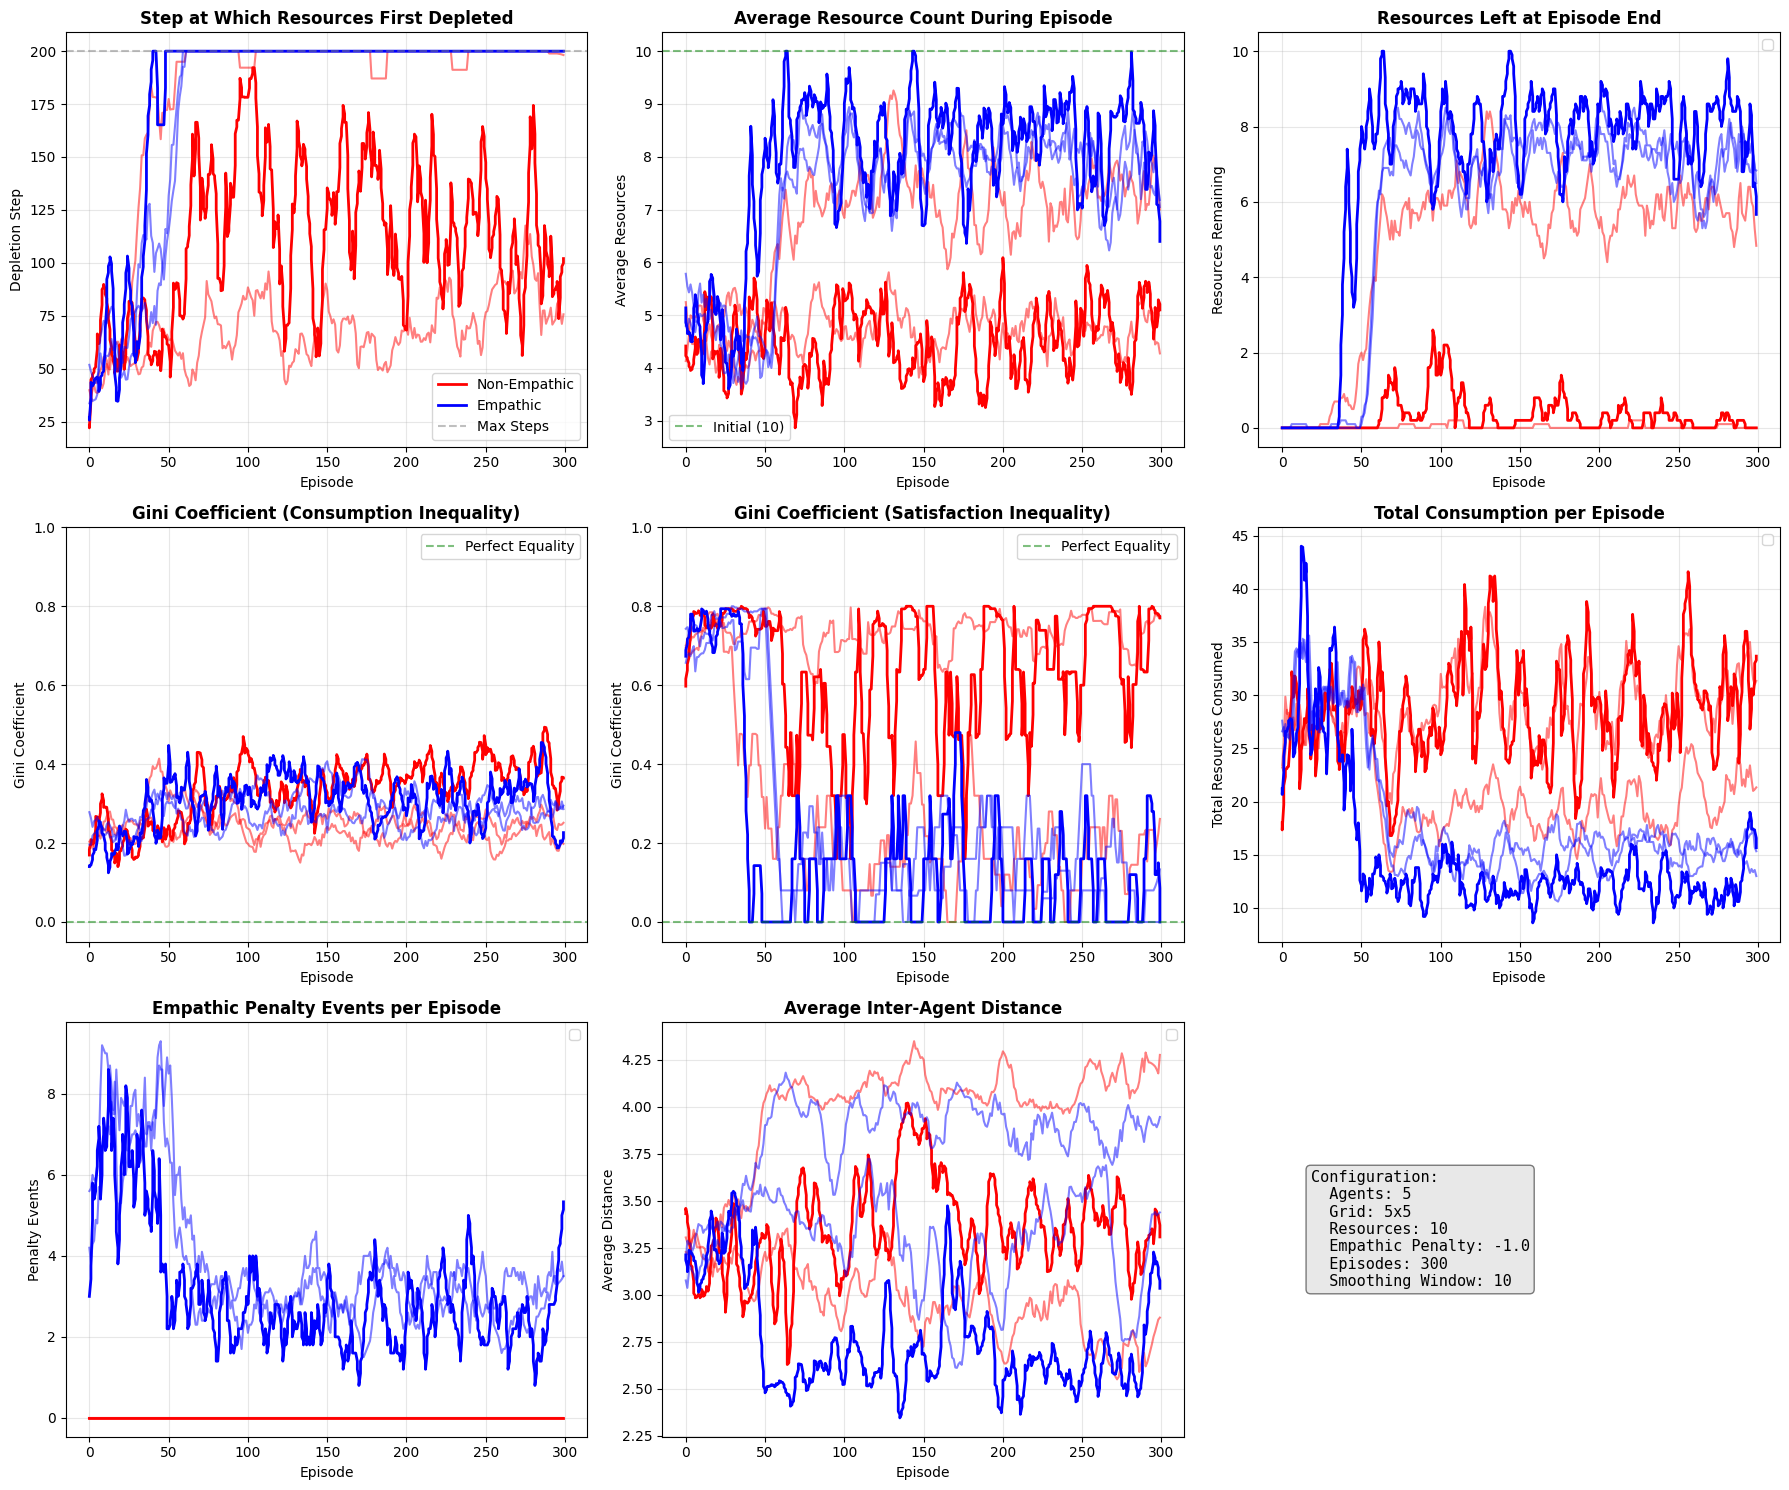

In [6]:
def smooth(data, window=10):
    """Apply centered moving average smoothing."""
    return data.rolling(window=window, min_periods=1, center=True).mean()


if len(df) > 0 and len(df['alpha'].unique()) >= 2:
    fig, axes = plt.subplots(3, 3, figsize=(18, 15))
    window = 10
    
    colors = {0.0: 'red', 0.5: 'blue'}
    labels = {0.0: 'Non-Empathic', 0.5: 'Empathic'}
    
    for alpha in sorted(df['alpha'].unique()):
        alpha_data = df[df['alpha'] == alpha]
        color = colors.get(alpha, 'green')
        base_label = labels.get(alpha, f'Alpha={alpha}')
        
        # Get unique simulations for this alpha
        simulations = sorted(alpha_data['simulation_number'].unique())
        
        # Plot each simulation separately
        for sim_num in simulations:
            sim_data = alpha_data[alpha_data['simulation_number'] == sim_num].sort_values('episode')
            episodes = sim_data['episode']
            
            # Use transparency to distinguish simulations (first sim is darker, others lighter)
            alpha_transparency = 1.0 if sim_num == simulations[0] else 0.5
            linewidth = 2 if sim_num == simulations[0] else 1.5
            label = base_label if sim_num == simulations[0] else None  # Only label first sim to avoid clutter
            
            # Row 1
            axes[0, 0].plot(episodes, smooth(sim_data['depletion_step'], window), 
                            color=color, linewidth=linewidth, alpha=alpha_transparency, label=label)
            axes[0, 1].plot(episodes, smooth(sim_data['avg_resources_during_episode'], window), 
                            color=color, linewidth=linewidth, alpha=alpha_transparency)
            axes[0, 2].plot(episodes, smooth(sim_data['resources_remaining'], window), 
                            color=color, linewidth=linewidth, alpha=alpha_transparency)
            
            # Row 2
            axes[1, 0].plot(episodes, smooth(sim_data['gini_consumption'], window), 
                            color=color, linewidth=linewidth, alpha=alpha_transparency)
            axes[1, 1].plot(episodes, smooth(sim_data['gini_satisfaction'], window), 
                            color=color, linewidth=linewidth, alpha=alpha_transparency)
            axes[1, 2].plot(episodes, smooth(sim_data['total_consumption'], window), 
                            color=color, linewidth=linewidth, alpha=alpha_transparency)
            
            # Row 3
            axes[2, 0].plot(episodes, smooth(sim_data['empathic_penalties_count'], window), 
                            color=color, linewidth=linewidth, alpha=alpha_transparency)
            axes[2, 1].plot(episodes, smooth(sim_data['avg_inter_agent_distance'], window), 
                            color=color, linewidth=linewidth, alpha=alpha_transparency)
    
    # Configure axes - Row 1
    axes[0, 0].axhline(y=MAX_STEPS, color='gray', linestyle='--', alpha=0.5, label='Max Steps')
    axes[0, 0].set_xlabel('Episode')
    axes[0, 0].set_ylabel('Depletion Step')
    axes[0, 0].set_title('Step at Which Resources First Depleted', fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    axes[0, 1].axhline(y=NUM_RESOURCES, color='green', linestyle='--', alpha=0.5, label=f'Initial ({NUM_RESOURCES})')
    axes[0, 1].set_xlabel('Episode')
    axes[0, 1].set_ylabel('Average Resources')
    axes[0, 1].set_title('Average Resource Count During Episode', fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    axes[0, 2].set_xlabel('Episode')
    axes[0, 2].set_ylabel('Resources Remaining')
    axes[0, 2].set_title('Resources Left at Episode End', fontweight='bold')
    axes[0, 2].legend()
    axes[0, 2].grid(True, alpha=0.3)
    
    # Configure axes - Row 2
    axes[1, 0].axhline(y=0, color='green', linestyle='--', alpha=0.5, label='Perfect Equality')
    axes[1, 0].set_xlabel('Episode')
    axes[1, 0].set_ylabel('Gini Coefficient')
    axes[1, 0].set_title('Gini Coefficient (Consumption Inequality)', fontweight='bold')
    axes[1, 0].set_ylim(-0.05, 1.0)
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    axes[1, 1].axhline(y=0, color='green', linestyle='--', alpha=0.5, label='Perfect Equality')
    axes[1, 1].set_xlabel('Episode')
    axes[1, 1].set_ylabel('Gini Coefficient')
    axes[1, 1].set_title('Gini Coefficient (Satisfaction Inequality)', fontweight='bold')
    axes[1, 1].set_ylim(-0.05, 1.0)
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    axes[1, 2].set_xlabel('Episode')
    axes[1, 2].set_ylabel('Total Resources Consumed')
    axes[1, 2].set_title('Total Consumption per Episode', fontweight='bold')
    axes[1, 2].legend()
    axes[1, 2].grid(True, alpha=0.3)
    
    # Configure axes - Row 3
    axes[2, 0].set_xlabel('Episode')
    axes[2, 0].set_ylabel('Penalty Events')
    axes[2, 0].set_title('Empathic Penalty Events per Episode', fontweight='bold')
    axes[2, 0].legend()
    axes[2, 0].grid(True, alpha=0.3)
    
    axes[2, 1].set_xlabel('Episode')
    axes[2, 1].set_ylabel('Average Distance')
    axes[2, 1].set_title('Average Inter-Agent Distance', fontweight='bold')
    axes[2, 1].legend()
    axes[2, 1].grid(True, alpha=0.3)
    
    # Summary panel
    axes[2, 2].axis('off')
    summary_text = f"""Configuration:
  Agents: {NB_AGENTS}
  Grid: {GRID_SIZE}x{GRID_SIZE}
  Resources: {NUM_RESOURCES}
  Empathic Penalty: {EMPATHIC_PENALTY}
  Episodes: {NUM_EPISODES}
  Smoothing Window: {window}"""
    
    axes[2, 2].text(0.1, 0.5, summary_text, ha='left', va='center',
                    transform=axes[2, 2].transAxes, fontsize=11, family='monospace',
                    bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.5))
    
    plt.tight_layout()
    plt.show()

## Statistical Comparison

In [7]:
last_n = 20

if len(df) > 0 and len(df['alpha'].unique()) >= 2:
    max_episode = df['episode'].max()
    last_episodes = df[df['episode'] > max_episode - last_n]
    
    ne_data = last_episodes[last_episodes['alpha'] == 0.0]
    e_data = last_episodes[last_episodes['alpha'] > 0]
    
    print(f"{'='*60}")
    print(f"STATISTICAL COMPARISON (Last {last_n} Episodes)")
    print(f"{'='*60}")
    
    def compare_metric(name, col):
        ne_vals = ne_data[col].dropna()
        e_vals = e_data[col].dropna()
        
        if len(ne_vals) == 0 or len(e_vals) == 0:
            print(f"\n{name}: Insufficient data")
            return
        
        ne_mean, ne_std = ne_vals.mean(), ne_vals.std()
        e_mean, e_std = e_vals.mean(), e_vals.std()
        
        # Mann-Whitney U test
        try:
            stat, p_value = stats.mannwhitneyu(ne_vals, e_vals, alternative='two-sided')
            sig = "" 
            if p_value < 0.05: sig = "*"
            if p_value < 0.01: sig = "**"
            if p_value < 0.001: sig = "***"
        except:
            p_value = 1.0
            sig = ""
        
        pct_change = (e_mean - ne_mean) / (ne_mean + 1e-6) * 100
        
        print(f"\n{name}:")
        print(f"  Non-Empathic: {ne_mean:.3f} +/- {ne_std:.3f}")
        print(f"  Empathic:     {e_mean:.3f} +/- {e_std:.3f}")
        print(f"  Difference:   {e_mean - ne_mean:+.3f} ({pct_change:+.1f}%)")
        print(f"  p-value:      {p_value:.4f} {sig}")
    
    compare_metric("Depletion Step", "depletion_step")
    compare_metric("Resources Remaining", "resources_remaining")
    compare_metric("Avg Resources During Episode", "avg_resources_during_episode")
    compare_metric("Gini (Consumption)", "gini_consumption")
    compare_metric("Gini (Satisfaction)", "gini_satisfaction")
    compare_metric("Avg Inter-Agent Distance", "avg_inter_agent_distance")
    compare_metric("Total Consumption", "total_consumption")
    compare_metric("Empathic Penalty Events", "empathic_penalties_count")
    
    print(f"\n{'='*60}")
    print("Significance: * p<0.05, ** p<0.01, *** p<0.001")
    print(f"{'='*60}")

STATISTICAL COMPARISON (Last 20 Episodes)

Depletion Step:
  Non-Empathic: 120.443 +/- 62.321
  Empathic:     200.000 +/- 0.000
  Difference:   +79.557 (+66.1%)
  p-value:      0.0000 ***

Resources Remaining:
  Non-Empathic: 1.468 +/- 2.796
  Empathic:     7.600 +/- 2.347
  Difference:   +6.132 (+417.6%)
  p-value:      0.0000 ***

Avg Resources During Episode:
  Non-Empathic: 5.541 +/- 1.939
  Empathic:     8.040 +/- 1.977
  Difference:   +2.499 (+45.1%)
  p-value:      0.0000 ***

Gini (Consumption):
  Non-Empathic: 0.316 +/- 0.139
  Empathic:     0.303 +/- 0.116
  Difference:   -0.013 (-4.3%)
  p-value:      0.6455 

Gini (Satisfaction):
  Non-Empathic: 0.583 +/- 0.335
  Empathic:     0.080 +/- 0.229
  Difference:   -0.503 (-86.3%)
  p-value:      0.0000 ***

Avg Inter-Agent Distance:
  Non-Empathic: 3.352 +/- 0.630
  Empathic:     3.175 +/- 0.559
  Difference:   -0.177 (-5.3%)
  p-value:      0.1073 

Total Consumption:
  Non-Empathic: 28.924 +/- 11.379
  Empathic:     14.550 +/- 

## Learning Curves

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


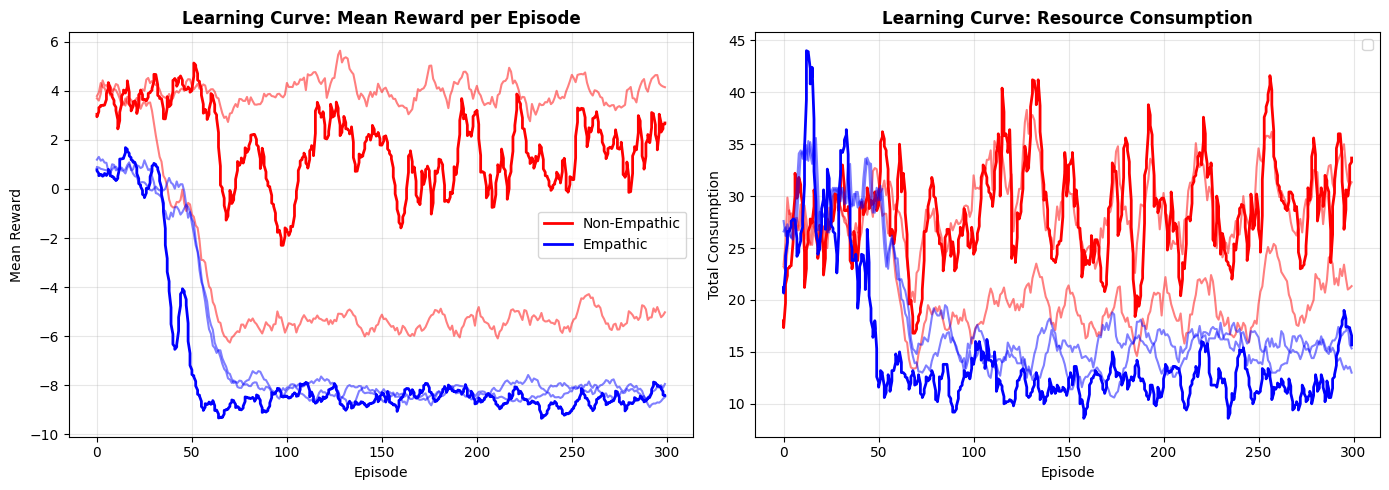

In [8]:
if len(df) > 0:
    # Compute mean reward per episode
    reward_cols = [f'total_reward_{i}' for i in range(NB_AGENTS)]
    df['mean_reward'] = df[reward_cols].mean(axis=1)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    window = 10
    
    colors = {0.0: 'red', 0.5: 'blue'}
    labels = {0.0: 'Non-Empathic', 0.5: 'Empathic'}
    
    for alpha in sorted(df['alpha'].unique()):
        alpha_data = df[df['alpha'] == alpha]
        color = colors.get(alpha, 'green')
        base_label = labels.get(alpha, f'Alpha={alpha}')
        
        # Get unique simulations for this alpha
        simulations = sorted(alpha_data['simulation_number'].unique())
        
        # Plot each simulation separately
        for sim_num in simulations:
            sim_data = alpha_data[alpha_data['simulation_number'] == sim_num].sort_values('episode')
            episodes = sim_data['episode']
            
            # Use transparency to distinguish simulations
            alpha_transparency = 1.0 if sim_num == simulations[0] else 0.5
            linewidth = 2 if sim_num == simulations[0] else 1.5
            label = base_label if sim_num == simulations[0] else None
            
            # Mean reward
            axes[0].plot(episodes, smooth(sim_data['mean_reward'], window),
                         color=color, linewidth=linewidth, alpha=alpha_transparency, label=label)
            
            # Total consumption (as proxy for activity)
            axes[1].plot(episodes, smooth(sim_data['total_consumption'], window),
                         color=color, linewidth=linewidth, alpha=alpha_transparency)
    
    axes[0].set_xlabel('Episode')
    axes[0].set_ylabel('Mean Reward')
    axes[0].set_title('Learning Curve: Mean Reward per Episode', fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    axes[1].set_xlabel('Episode')
    axes[1].set_ylabel('Total Consumption')
    axes[1].set_title('Learning Curve: Resource Consumption', fontweight='bold')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

## Distribution Analysis (Final Episodes)

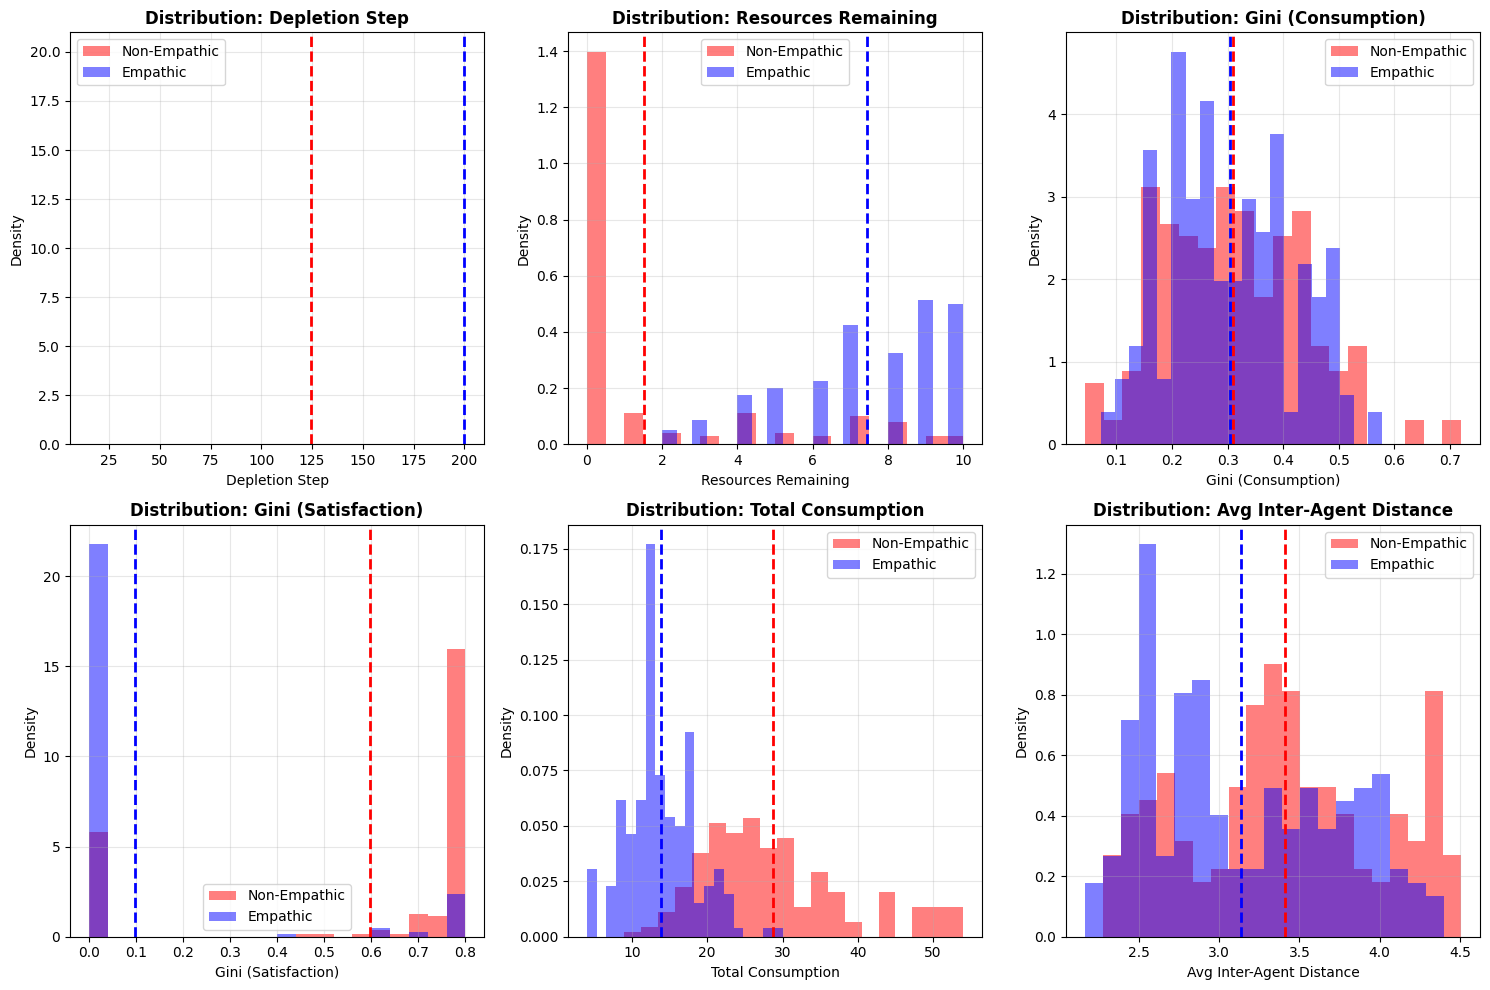


Distributions based on last 50 episodes


In [9]:
last_n = 50

if len(df) > 0 and len(df['alpha'].unique()) >= 2:
    max_episode = df['episode'].max()
    last_episodes = df[df['episode'] > max_episode - last_n]
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    metrics = [
        ('depletion_step', 'Depletion Step'),
        ('resources_remaining', 'Resources Remaining'),
        ('gini_consumption', 'Gini (Consumption)'),
        ('gini_satisfaction', 'Gini (Satisfaction)'),
        ('total_consumption', 'Total Consumption'),
        ('avg_inter_agent_distance', 'Avg Inter-Agent Distance'),
    ]
    
    for idx, (col, title) in enumerate(metrics):
        ax = axes[idx // 3, idx % 3]
        
        ne_data = last_episodes[last_episodes['alpha'] == 0.0][col]
        e_data = last_episodes[last_episodes['alpha'] > 0][col]
        
        ax.hist(ne_data, bins=20, alpha=0.5, color='red', label='Non-Empathic', density=True)
        ax.hist(e_data, bins=20, alpha=0.5, color='blue', label='Empathic', density=True)
        
        ax.axvline(ne_data.mean(), color='red', linestyle='--', linewidth=2)
        ax.axvline(e_data.mean(), color='blue', linestyle='--', linewidth=2)
        
        ax.set_xlabel(title)
        ax.set_ylabel('Density')
        ax.set_title(f'Distribution: {title}', fontweight='bold')
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

    print(f"\nDistributions based on last {last_n} episodes")

## Per-Agent Analysis

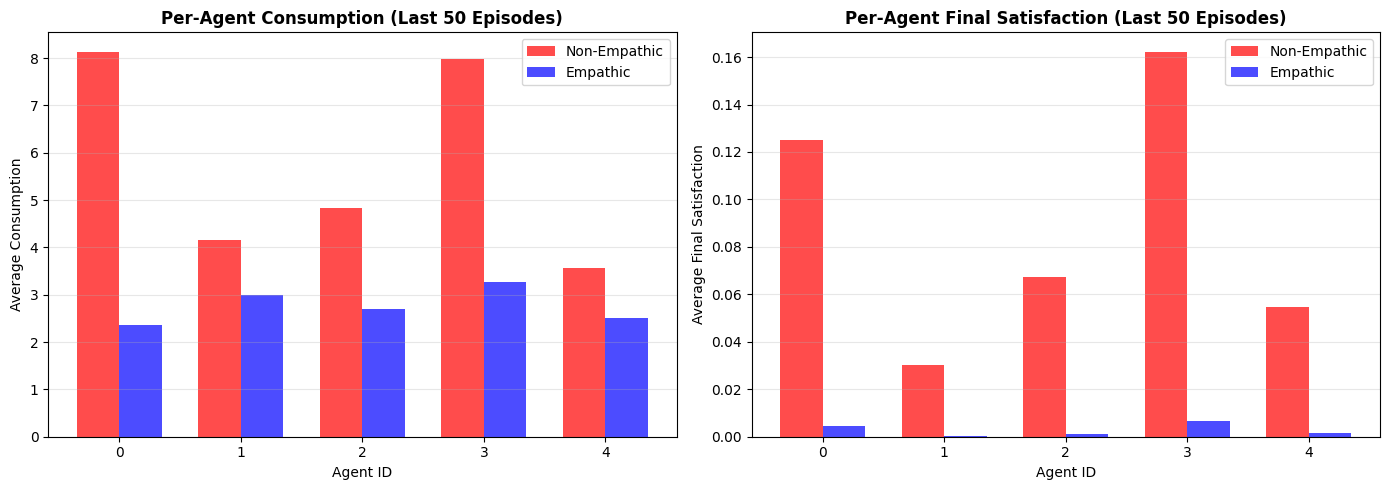

In [10]:
last_n = 50

if len(df) > 0:
    max_episode = df['episode'].max()
    last_episodes = df[df['episode'] > max_episode - last_n]
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Per-agent consumption comparison
    consumption_cols = [f'consumption_per_agent_{i}' for i in range(NB_AGENTS)]
    
    ne_consumption = last_episodes[last_episodes['alpha'] == 0.0][consumption_cols].mean()
    e_consumption = last_episodes[last_episodes['alpha'] > 0][consumption_cols].mean()
    
    x = np.arange(NB_AGENTS)
    width = 0.35
    
    axes[0].bar(x - width/2, ne_consumption.values, width, label='Non-Empathic', color='red', alpha=0.7)
    axes[0].bar(x + width/2, e_consumption.values, width, label='Empathic', color='blue', alpha=0.7)
    axes[0].set_xlabel('Agent ID')
    axes[0].set_ylabel('Average Consumption')
    axes[0].set_title('Per-Agent Consumption (Last 50 Episodes)', fontweight='bold')
    axes[0].set_xticks(x)
    axes[0].legend()
    axes[0].grid(True, alpha=0.3, axis='y')
    
    # Per-agent satisfaction comparison
    satisfaction_cols = [f'final_satisfaction_{i}' for i in range(NB_AGENTS)]
    
    ne_satisfaction = last_episodes[last_episodes['alpha'] == 0.0][satisfaction_cols].mean()
    e_satisfaction = last_episodes[last_episodes['alpha'] > 0][satisfaction_cols].mean()
    
    axes[1].bar(x - width/2, ne_satisfaction.values, width, label='Non-Empathic', color='red', alpha=0.7)
    axes[1].bar(x + width/2, e_satisfaction.values, width, label='Empathic', color='blue', alpha=0.7)
    axes[1].set_xlabel('Agent ID')
    axes[1].set_ylabel('Average Final Satisfaction')
    axes[1].set_title('Per-Agent Final Satisfaction (Last 50 Episodes)', fontweight='bold')
    axes[1].set_xticks(x)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()